In [4]:
df <- readRDS("C:/Users/Bahissou TCHAGNAO/Desktop/DOSSIER_DES_PROJETS/Biomethane_FR/data/data_clean.rds")
dim(df)   # attendu : 257086 20

[1] 257086     20

In [6]:
library(dplyr)
library(tidyr)
library(zoo)
library(ggplot2)
library(tseries)
library(forecast)

In [7]:


df_propre <- df %>%
  # 1) On sépare le jour et l'heure "sur l'horloge" (ex : "02:30")
  mutate(date  = as.Date(date_time, tz = "Europe/Paris"),
         heure = format(date_time, "%H:%M", tz = "Europe/Paris")) %>%

  # 2) Octobre : deux lignes ont le même jour + la même heure
  #    -> on demande à R d'en faire une seule, avec la moyenne
  group_by(date, heure) %>%
  summarise(consommation = mean(consommation, na.rm = TRUE),
            .groups = "drop") %>%

  # 3) Mars : on oblige R à avoir les 48 heures pour chaque jour.
  #    Les heures absentes sont créées avec une valeur vide (NA)
  complete(date,
           heure = format(seq(as.POSIXct("2000-01-01 00:00", tz = "UTC"),
                              by = "30 min", length.out = 48), "%H:%M")) %>%
  arrange(date, heure) %>%

  # 4) On remplit chaque NA en traçant une ligne droite
  #    entre la valeur d'avant et celle d'après
  mutate(consommation = na.approx(consommation, na.rm = FALSE))

# Vérification : on doit obtenir uniquement des 48
df_propre %>% count(date) %>% count(n)




Storing counts in `nn`, as `n` already present in input
ℹ Use `name = "new_name"` to pick a new name.


n,nn
<int>,<int>
48,5357


In [11]:
library(dplyr)
library(lubridate)

data<- df_propre %>%
  group_by(date) %>%                          # un paquet par jour
  summarise(conso_moy = mean(consommation),   # moyenne des 48 demi-heures
            .groups = "drop") %>%
  filter(date >= as.Date("2018-01-01")) %>%   # on garde depuis 2018
  mutate(annee        = year(date),
         mois         = month(date),
         jour_semaine = wday(date, week_start = 1),   # 1 = lundi ... 7 = dimanche
         est_weekend  = as.integer(jour_semaine >= 6)) %>%
  arrange(date)

# Contrôles
nrow(data)               # nombre de jours
range(data$date)         # première et dernière date
summary(data$conso_moy)  # min, moyenne, max
head(data, 3)            # aperçu des premières lignes

[1] 3165

[1] "2018-01-01" "2026-08-31"

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  35619   44244   48146   51690   59028   89600 

date,conso_moy,annee,mois,jour_semaine,est_weekend
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
2018-01-01,56302.04,2018,1,1,0
2018-01-02,63102.96,2018,1,2,0
2018-01-03,63761.27,2018,1,3,0


In [12]:

data$est_weekend = as.factor(data$est_weekend)

dim(data)


[1] 3165    6

In [13]:
# On arrondit pour éviter les problèmes de virgule/point dans Power BI
export_bi <- data %>%
  mutate(conso_moy = round(conso_moy, 0))

# On écrit un CSV avec ";" comme séparateur et "," comme décimale
# (format qu'Excel et Power BI en français lisent directement)
write.csv2(export_bi, "conso_jour_historique.csv", row.names = FALSE)

In [14]:
conso=  data[, c("date","conso_moy")]



Y=  ts(data$conso_moy, start = c(data$annee,data$mois,data$jour_semaine),frequency = 7)

[1] 365

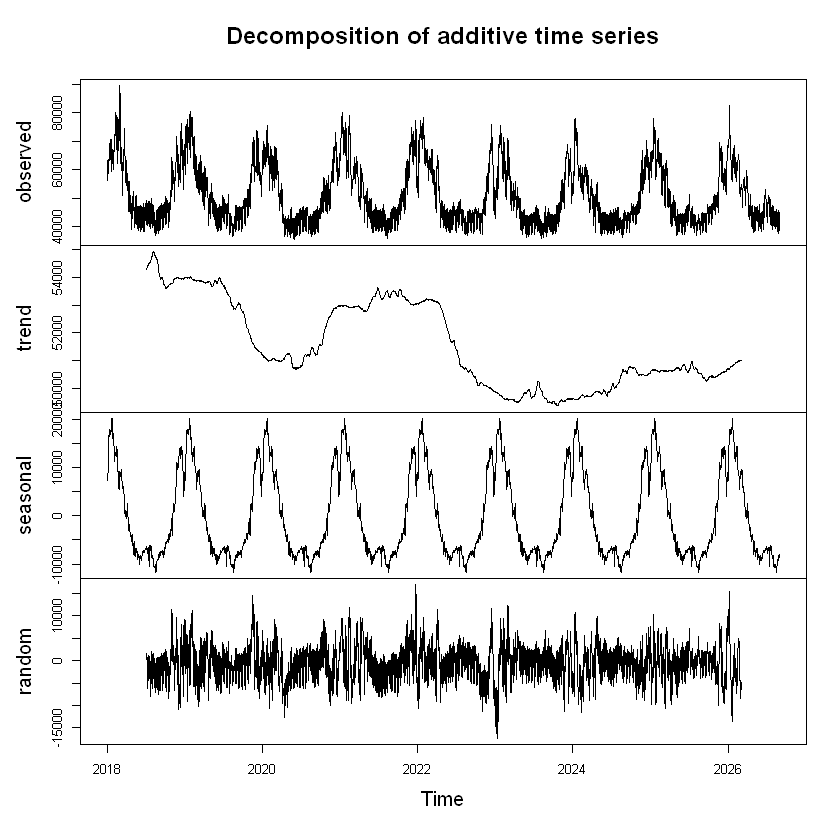

In [15]:
# On repart des valeurs seules (sans la date), avec une fréquence annuelle
serie365 <- ts(data$conso_moy, frequency = 365, start = c(2018, 1))

frequency(serie365)          # doit afficher 365
d=decompose(serie365)
plot(d)    # l'axe doit aller de 2018 à 2026

La décomposition additive met en évidence une tendance évolutive, caractérisée par plusieurs phases de diminution et de reprise de la consommation. La composante saisonnière présente un cycle annuel fortement marqué et relativement régulier. Enfin, les résidus montrent des fluctuations importantes autour de zéro, avec quelques variations extrêmes. Ces observations suggèrent que la série présente une saisonnalité importante et une tendance non constante, des caractéristiques à prendre en compte lors de la modélisation. La  stationnarité  de  la serie  est  donc  douteuse.


### L  consommation  varie  t-elle selon  le  jour ?  le  mois ?

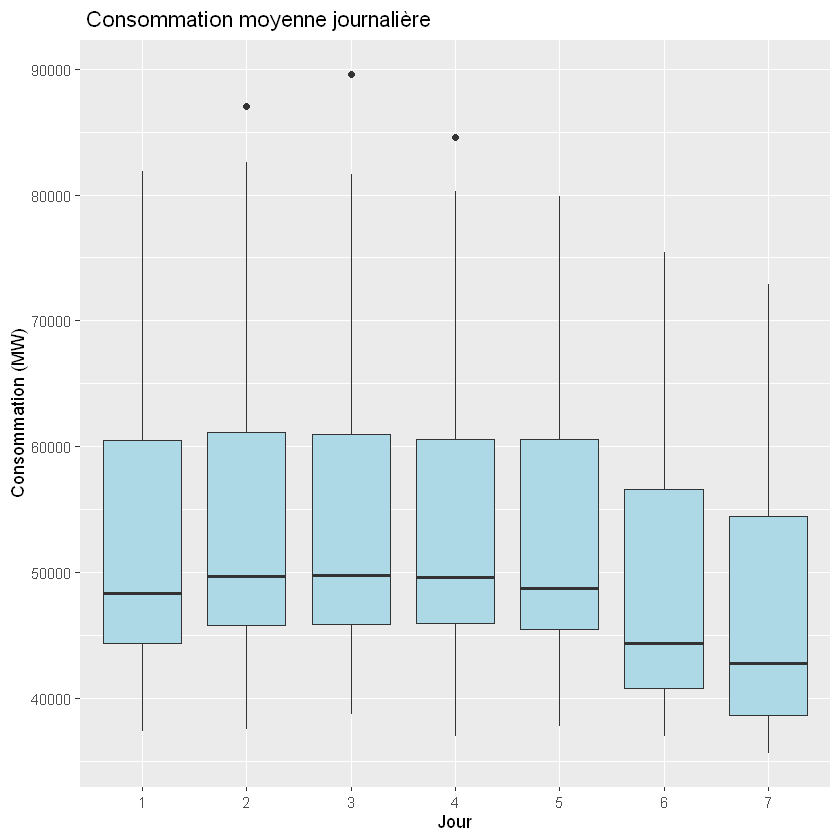

In [16]:
ggplot(data,  aes(x=  factor(jour_semaine), y = conso_moy))  +
geom_boxplot(fill = "lightblue" )+
labs(  title  =" Consommation moyenne journalière",
        x = "Jour",
        y  =  "Consommation (MW)")

La  consommation en jour  de  la  seamine  est  legerement  au  dessus  de  celle  des weekend.  

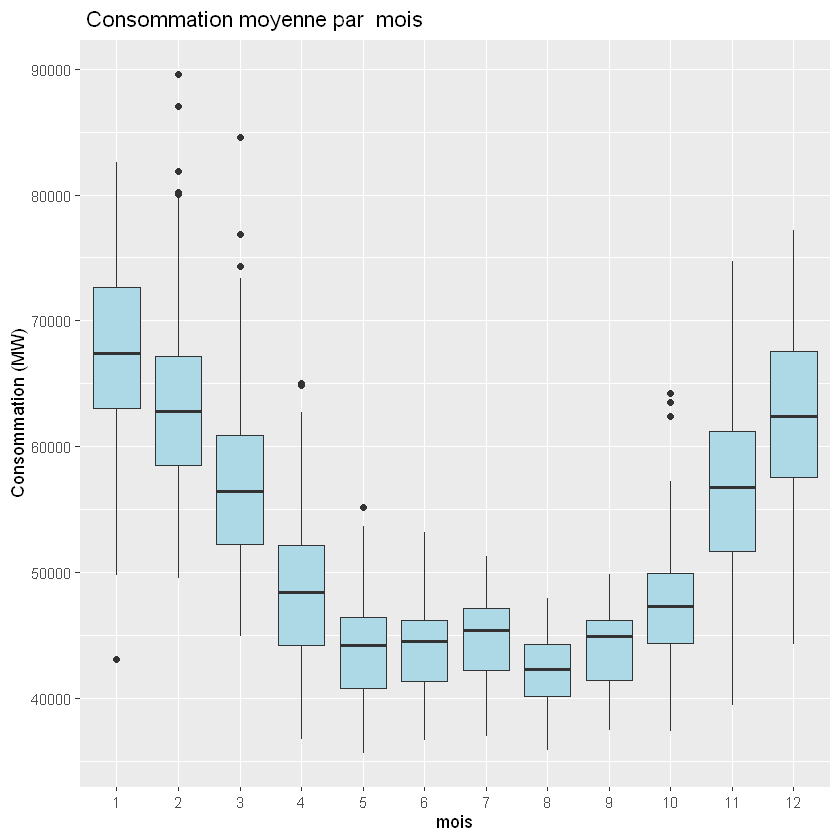

In [17]:
ggplot(data,  aes(x=  factor(mois), y = conso_moy))  +
geom_boxplot(fill = "lightblue" )+
labs(  title  =" Consommation moyenne par  mois",
        x = "mois",
        y  =  "Consommation (MW)")

In [18]:
effet_weekend  = data %>%
              group_by(est_weekend) %>%
              summarise(
                          moyenne = mean(conso_moy),
                          mediane = median(conso_moy),
                          ecart_type = sd(conso_moy),
                          minimum = min(conso_moy),
                          maximum = max(conso_moy),
                          .groups =  "drop"
              
                        )

 effet_weekend             

est_weekend,moyenne,mediane,ecart_type,minimum,maximum
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,53275.16,49297.58,9920.147,36955.00,89600.08
1,47724.75,43738.62,9654.525,35618.71,75460.00


In [19]:
((effet_weekend$moyenne[1]-effet_weekend$moyenne[2])/effet_weekend$moyenne[2])*100


[1] 11.63003

L'analyse  des  distributions  mensuelle  met  en evidence  une  saisonnalité annuelle marquée,  caracterisée  par des  consommations  plus   élevées  en hiver  et  plus  faible  en  été.  Une  reprise  progtessive  est  observée  à partie  de septembre. Par  ailleur  la  comparaison selon les  jours  de la semaine  revele  un  effet  hebdomadaire :  les  consommations  medianes  sont  globalement plus  élevé  du lundi  au vendredi,  puis  dimunie  le weekend. On a  environ 11,63 %  de plus qu'en weekend. Enfin on observe  plusieurs  valeurs  atypiques, notamment  en février, mars  et  octobre  suggerant  une  forte  consommation exceptionnelle.  Ces  resultats  confirment  la  présence  de  structures  saisonnière: hebdomadaire  et  annuelle.

2c-L  serie  est  elle  stationnaire  ?  pourquoi ?  que    faire  ?  

In [28]:
serie7 = ts(data$conso_moy, start = c(2018, 1), frequency = 7)

serie365 = ts(data$conso_moy, start = c(2018, 1), frequency = 365)

In [29]:



print("\n==Test  de  stationnarité (serie7)")
adf.test(serie7)
kpss.test(serie7)
print("\n==Test  de  stationnarité (serie365)")
adf.test(serie365)
kpss.test(serie365)

[1] "\n==Test  de  stationnarité (serie7)"


Warning message in adf.test(serie7):
"p-value smaller than printed p-value"



	Augmented Dickey-Fuller Test

data:  serie7
Dickey-Fuller = -4.9722, Lag order = 14, p-value = 0.01
alternative hypothesis: stationary


Warning message in kpss.test(serie7):
"p-value smaller than printed p-value"



	KPSS Test for Level Stationarity

data:  serie7
KPSS Level = 0.93127, Truncation lag parameter = 9, p-value = 0.01


[1] "\n==Test  de  stationnarité (serie365)"


Warning message in adf.test(serie365):
"p-value smaller than printed p-value"



	Augmented Dickey-Fuller Test

data:  serie365
Dickey-Fuller = -4.9722, Lag order = 14, p-value = 0.01
alternative hypothesis: stationary


Warning message in kpss.test(serie365):
"p-value smaller than printed p-value"



	KPSS Test for Level Stationarity

data:  serie365
KPSS Level = 0.93127, Truncation lag parameter = 9, p-value = 0.01


Les tests de stationnarité appliqués à la série brute donnent des conclusions contradictoires : le test ADF rejette l'hypothèse de présence d'une racine unitaire (p-value inférieure à 0,01), tandis que le test KPSS rejette l'hypothèse de stationnarité autour d'un niveau constant (p-value inférieure à 0,01). Ces résultats suggèrent que la série présente une structure temporelle complexe, caractérisée notamment par une forte saisonnalité et des variations de son niveau moyen. La série brute ne peut donc pas être considérée comme stationnaire sur la seule base de ces tests. Une analyse complémentaire est nécessaire afin de déterminer si une transformation et une différenciation, notamment saisonnière, sont nécessaires avant la modélisation.

#Nous  allons  chercher le  nombre  de differentiation  neccaire  pour  rendre  la  serie  stationnaire

In [30]:
nsdiffs(serie7)
nsdiffs(serie365)

[1] 1

[1] 1

In [33]:
serie7_d7=  diff(serie7,lag=7)
serie365_d365=  diff(serie365,lag=365)

In [34]:
ndiffs(serie365_d365)
ndiffs(serie7_d7)

[1] 0

[1] 0

In [35]:
adf.test(serie7_d7)
kpss.test(serie7_d7)


Warning message in adf.test(serie7_d7):
"p-value smaller than printed p-value"



	Augmented Dickey-Fuller Test

data:  serie7_d7
Dickey-Fuller = -13.142, Lag order = 14, p-value = 0.01
alternative hypothesis: stationary


Warning message in kpss.test(serie7_d7):
"p-value greater than printed p-value"



	KPSS Test for Level Stationarity

data:  serie7_d7
KPSS Level = 0.014031, Truncation lag parameter = 9, p-value = 0.1


Après une différenciation saisonnière de période 7, les tests ADF (p-value < 0,01) et KPSS (p-value > 0,10) indiquent que la série est désormais stationnaire en moyenne. La différenciation hebdomadaire semble donc suffisante pour stabiliser la moyenne de la série.

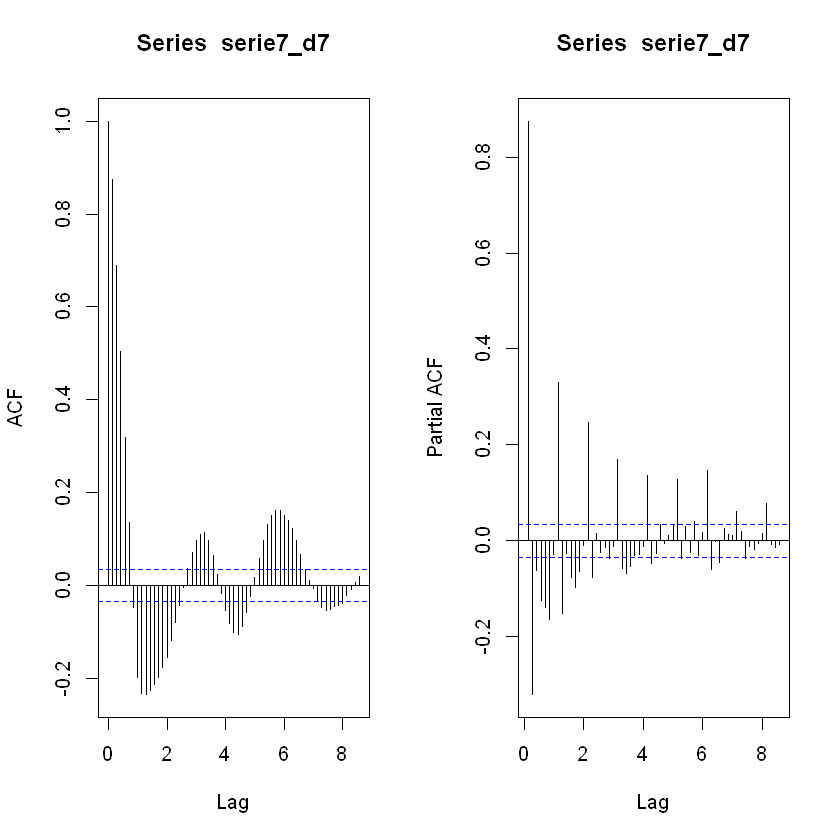

In [36]:


par(mfrow= c(1,2))
acf(serie7_d7, lag.max = 60)
pacf(serie7_d7, lag.max = 60)

In [41]:
T = list(
  c(1,0,1, 1,1,0),
  c(1,0,2, 1,1,0),
  c(1,0,3, 1,1,0),
  c(2,0,1, 1,1,0),
  c(2,0,2, 1,1,0),
  c(2,0,3, 1,1,0),
  c(3,0,2, 1,1,0),
  c(3,0,3, 1,1,0),
  c(1,0,1, 0,1,1),
  c(1,0,2, 0,1,1),
  c(2,0,2, 0,1,1),
  c(2,0,3, 0,1,1),
   c(2,0,2, 1,1,1),
    c(2,0,2, 1,1,1),
     c(2,0,2, 2,1,1)
)



calcul_aic = function(p, d, q, P, D, Q, serie) {

  tryCatch({

    modele = arima(
      serie,
      order = c(p, d, q),
      seasonal = list(
        order = c(P, D, Q),
        period = 7
      )
    )

    data.frame(
      p = p, d = d, q = q,
      P = P, D = D, Q = Q,
      AIC = AIC(modele)
    )

  }, error = function(e) {

    data.frame(
      p = p, d = d, q = q,
      P = P, D = D, Q = Q,
      AIC = NA
    )

  })
}

In [42]:
resultats = do.call(rbind, lapply(T, function(param) {

  calcul_aic(
    p = param[1],
    d = param[2],
    q = param[3],
    P = param[4],
    D = param[5],
    Q = param[6],
    serie = serie7
  )

}))

In [43]:
resultats = resultats[order(resultats$AIC), ]

resultats

,p,d,q,P,D,Q,AIC
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
13,2,0,2,1,1,1,56227.87
14,2,0,2,1,1,1,56227.87
11,2,0,2,0,1,1,56228.19
12,2,0,3,0,1,1,56228.55
15,2,0,2,2,1,1,56229.37
9,1,0,1,0,1,1,56252.02
10,1,0,2,0,1,1,56252.02
8,3,0,3,1,1,0,56908.51
5,2,0,2,1,1,0,57097.46


In [44]:
modele =  Arima(serie7,order = c(2,0,2),seasonal = list(order=c(0,1,1), period=7))
R=modele$residuals


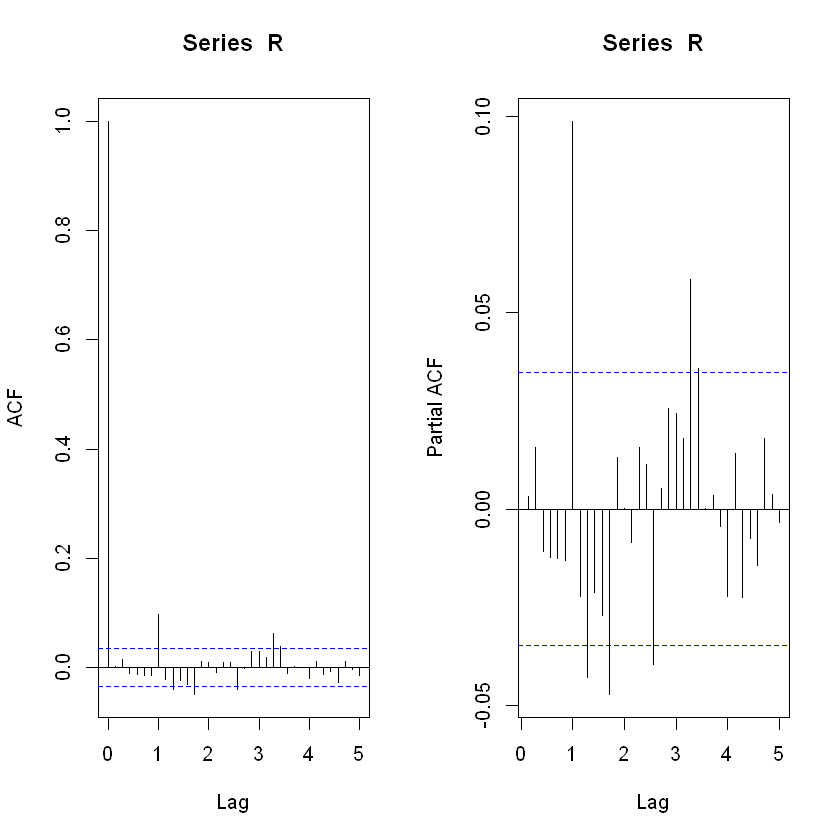

In [45]:
par(mfrow=c(1,2))
acf(R)
pacf(R)

In [46]:
Box.test(R,lag=49,type  =  "Ljung-Box", fitdf = 7)


	Box-Ljung test

data:  R
X-squared = 149.73, df = 42, p-value = 5.229e-14


In [47]:
shapiro.test(R)


	Shapiro-Wilk normality test

data:  R
W = 0.91215, p-value < 2.2e-16


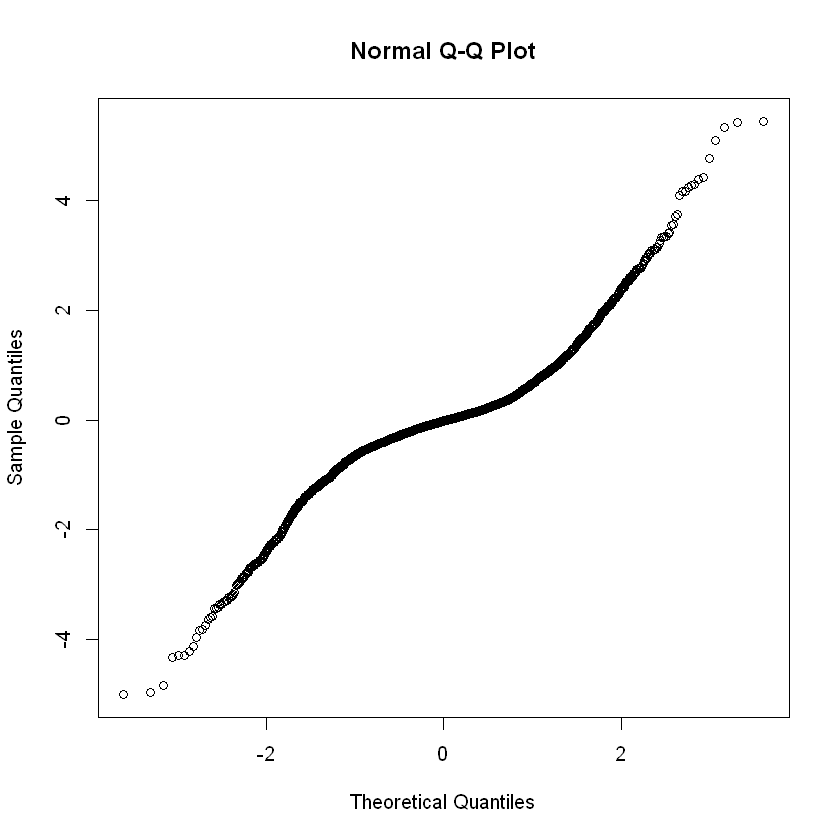

In [48]:
qqnorm(R/sd(R))

 Le test de Shapiro-Wilk rejette la normalité des résidus (W = 0.912, p < 2.2 × 10⁻¹⁶), ce qui s'explique par la grande taille de l'échantillon et la présence de valeurs extrêmes liées aux aléas climatiques et jours fériés sur le réseau RTE. Toutefois, la normalité n'étant pas requise pour garantir l'absence de biais de la prévision ponctuelle, nous conservons le modèle SARIMA(2,0,2)(0,1,1) pour l'étape de prévision, tout en gardant à l'esprit que les intervalles de prédiction à 95 % sont approximatifs. 

Nous  alons  passer  à  la prévison

In [55]:
n=  length(serie7)
n_test =  28
n_train=  n-n_test
serie_7_train= subset(serie7,end =n_train)
serie_7_test= subset(serie7,start =n_train+1)

In [56]:
modele7_train=Arima(serie_7_train, order=c(2,0,2), seasonal =list(order=c(0,1,1),period=7))

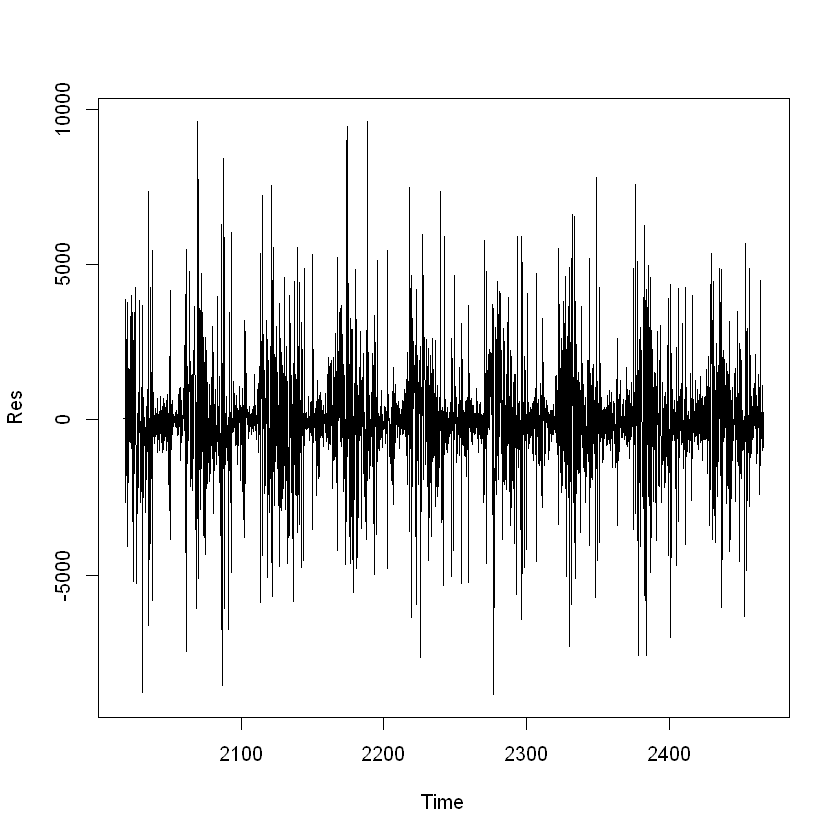

In [57]:
Res  =  modele7_train$residuals

plot(Res)

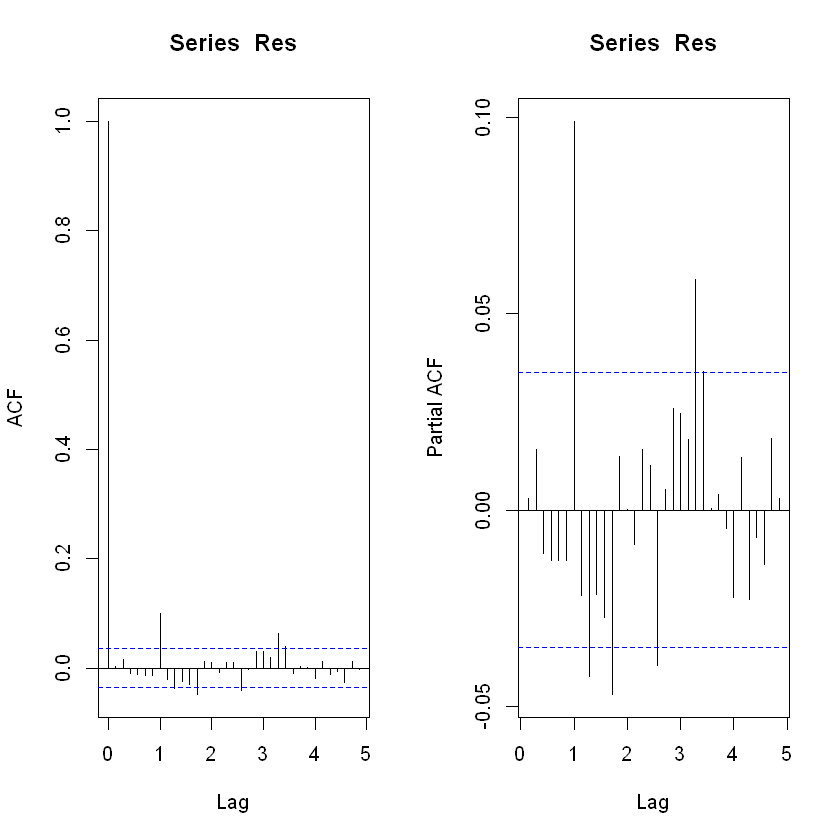

In [58]:
par(mfrow=c(1,2))
acf(Res)
pacf(Res)

In [59]:
Box.test(R,lag=49,type  =  "Ljung-Box", fitdf = 7)


	Box-Ljung test

data:  R
X-squared = 149.73, df = 42, p-value = 5.229e-14


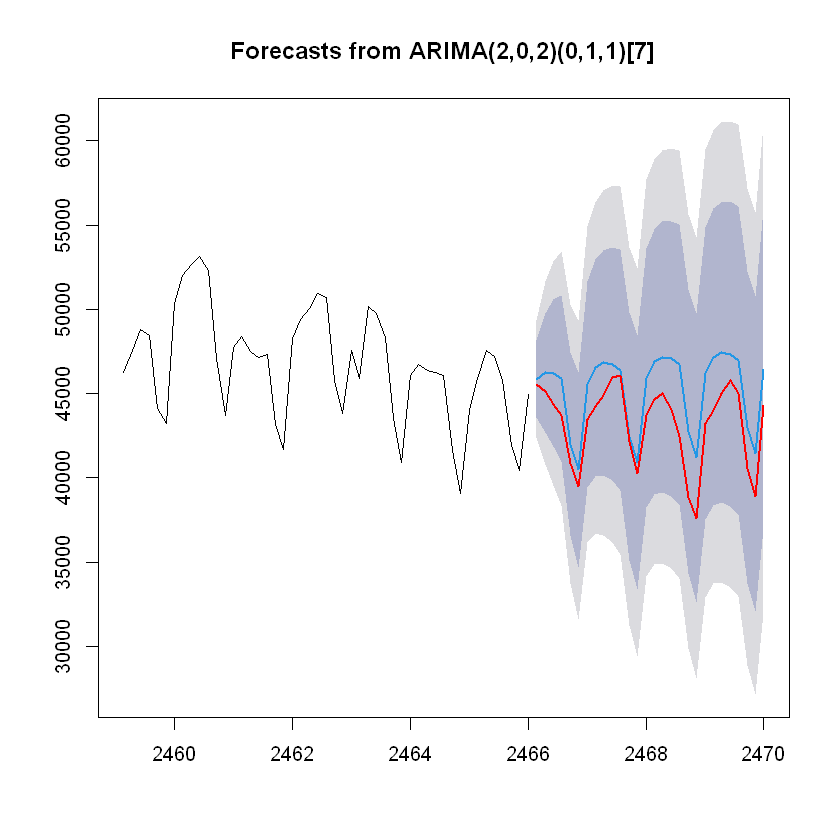

In [60]:
pred_train  =  forecast(modele7_train, h =n_test, level = c(80,95))
#  include  =56  pour  afficher  les  dernieres  56  valeurs
# soit  les  valeurs  des derniere  8 semaines du  jeu  d'entrainement
plot(pred_train, include = 49)
lines(serie_7_test, col = "red", lwd = 2)

In [63]:
accuracy(pred_train,serie_7_test)


,ME,RMSE,MAE,MPE,MAPE,MASE,ACF1,Theil's U
Training set,-15.49349,1773.884,1147.475,-0.1190735,2.168570,0.3357689,0.003063008,NA
Test set,-2021.44822,2274.786,2021.448,-4.7408815,4.740881,0.5915072,0.743446759,0.9045547


In [66]:

dates_test <- tail(as.Date(data$date), 28)


reel      <- as.numeric(serie_7_test)
prev      <- as.numeric(pred_train$mean)
ic95_bas  <- as.numeric(pred_train$lower[, 2])
ic95_haut <- as.numeric(pred_train$upper[, 2])

# 3. Construire le tableau plat pour Power BI
export_previsions <- data.frame(
  Date         = dates_test,
  Jour_Semaine = weekdays(dates_test),
  Horizon_Jour = 1:28,
  Reel_MW      = reel,
  Prevision_MW = prev,
  IC95_Bas     = ic95_bas,
  IC95_Haut    = ic95_haut,
  Erreur_MW    = reel - prev,
  MAPE_Jour    = abs((reel - prev) / reel) * 100
)


write.csv2(export_previsions, "previsions_sarima.csv", row.names = FALSE)
